In [1]:
# Install packages [26.10.2026]
import pandas as pd
import numpy as np

import statsmodels.api as sm
import statsmodels.formula.api as smf

from scipy import stats

import matplotlib.pyplot as plt

In [2]:
# Import data and look at the data frame
df = pd.read_csv(r"C:\Users\yalci\Documents\Home Credit Default Risk\german_credit_data.csv")

In [3]:
# Translate columns in english and look at the first five rows
columns = ['status','duration','credit_history','purpose','amount','savings',
          'employment_duration','installment_rate','personal_status_sex','other_debtors',
          'present_residence','property','age','other_installment_plans','housing',
          'number_credits','job','people_liable','telephone','foreign_worker','credit_risk']
df.columns = columns
print(df.head())

   status  duration  credit_history  purpose  amount  savings  \
0       1        18               4        2    1049        1   
1       1         9               4        0    2799        1   
2       2        12               2        9     841        2   
3       1        12               4        0    2122        1   
4       1        12               4        0    2171        1   

   employment_duration  installment_rate  personal_status_sex  other_debtors  \
0                    2                 4                    2              1   
1                    3                 2                    3              1   
2                    4                 2                    2              1   
3                    3                 3                    3              1   
4                    3                 4                    3              1   

   ...  property  age  other_installment_plans  housing  number_credits  job  \
0  ...         2   21                        3  

In [4]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   status                   1000 non-null   int64
 1   duration                 1000 non-null   int64
 2   credit_history           1000 non-null   int64
 3   purpose                  1000 non-null   int64
 4   amount                   1000 non-null   int64
 5   savings                  1000 non-null   int64
 6   employment_duration      1000 non-null   int64
 7   installment_rate         1000 non-null   int64
 8   personal_status_sex      1000 non-null   int64
 9   other_debtors            1000 non-null   int64
 10  present_residence        1000 non-null   int64
 11  property                 1000 non-null   int64
 12  age                      1000 non-null   int64
 13  other_installment_plans  1000 non-null   int64
 14  housing                  1000 non-null   int64
 15  number_credits  

In [5]:
# Checking if there are any missing values that could distort the results
df.isna().sum()

status                     0
duration                   0
credit_history             0
purpose                    0
amount                     0
savings                    0
employment_duration        0
installment_rate           0
personal_status_sex        0
other_debtors              0
present_residence          0
property                   0
age                        0
other_installment_plans    0
housing                    0
number_credits             0
job                        0
people_liable              0
telephone                  0
foreign_worker             0
credit_risk                0
dtype: int64

In [6]:
# RQ 1: Which demographic and financial characteristics influence credit risk?
    # Dependent variable: credit_risk
    # Independent variables 1.1: age, housing, job, savings, (credit) amount, 
                                # duration, purpose, personal_status_sex

In [7]:
# Look at the dependent variable
print(df['credit_risk'].value_counts())

# where 1 = low and 0 = high credit risk

credit_risk
1    700
0    300
Name: count, dtype: int64


In [8]:
# Define the regression formula
reg_dem = """credit_risk ~ age
            + C(job)
            + C(housing)
            + C(savings)
            + amount
            + duration
            + C(purpose)
            + C(personal_status_sex)"""

# C(.) instructs statsmodels to create dummy variables out of categoricals

In [9]:
# Selecting variables
demographic = df[
    [
        'age',
        'housing',
        'job',
        'savings',
        'amount',
        'duration',
        'purpose',
        'personal_status_sex',
        'credit_risk'
    ]
]

# By default, statsmodels creates k − 1 dummy variables, see results below

In [10]:
# Estimating the model
logit_model = smf.logit(formula=reg_dem, data=demographic)
results = logit_model.fit(cov_type="HC3")
print(results.summary())

Optimization terminated successfully.
         Current function value: 0.531456
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:            credit_risk   No. Observations:                 1000
Model:                          Logit   Df Residuals:                      975
Method:                           MLE   Df Model:                           24
Date:                Tue, 03 Nov 2026   Pseudo R-squ.:                  0.1300
Time:                        09:25:05   Log-Likelihood:                -531.46
converged:                       True   LL-Null:                       -610.86
Covariance Type:                  HC3   LLR p-value:                 7.489e-22
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                      -0.4778      0.710     -0.673      0.501   

In [11]:
rename_dict = {
    'C(job)[T.1]': 'Job: unemployed',
    'C(job)[T.2]': 'Job: unskilled',
    'C(job)[T.3]': 'Job: skilled',
    'C(job)[T.4]': 'Job: high position',
    'C(housing)[T.1]': 'Housing: for free',
    'C(housing)[T.2]': 'Housing: rent',
    'C(housing)[T.3]': 'Housing: own',
    'C(savings)[T.1]': 'Savings: none',
    'C(savings)[T.2]': 'Savings: < 100 DM',
    'C(savings)[T.3]': 'Savings: 100 to 500 DM',
    'C(savings)[T.4]': 'Savings: 500 to 1000 DM',
    'C(savings)[T.5]': 'Savings: ≥ 1000 DM',
    'C(purpose)[T.0]': 'Purpose: other',
    'C(purpose)[T.1]': 'Purpose: new car',
    'C(purpose)[T.2]': 'Purpose: used car',
    'C(purpose)[T.3]': 'Purpose: furniture',
    'C(purpose)[T.4]': 'Purpose: radio/TV',
    'C(purpose)[T.5]': 'Purpose: domestic appliances',
    'C(purpose)[T.6]': 'Purpose: repairs',
    'C(purpose)[T.7]': 'Purpose: education',
    'C(purpose)[T.8]': 'Purpose: vacation',
    'C(purpose)[T.9]': 'Purpose: retraining',
    'C(purpose)[T.10]': 'Purpose: business',
    'C(personal_status_sex)[T.2]': 'non-single f or single m',
    'C(personal_status_sex)[T.3]': 'married/widowed male',
    'C(personal_status_sex)[T.4]': 'single female'
}

In [12]:
# Obtain Odds Ratios
odds_ratios = pd.DataFrame({
    "Variable": results.params.index,
    "Coefficient": results.params.values,
    "Odds_Ratio": np.exp(results.params.values),
    "p_value": results.pvalues.values
})

odds_ratios["Variable"] = odds_ratios["Variable"].replace(rename_dict)
print(odds_ratios.to_string(formatters={"p_value": "{:.3g}".format}))

                        Variable  Coefficient  Odds_Ratio  p_value
0                      Intercept    -0.477810    0.620140    0.501
1                 Job: unskilled    -0.041507    0.959343    0.934
2                   Job: skilled     0.043604    1.044568    0.929
3             Job: high position    -0.077406    0.925514    0.883
4                  Housing: rent     0.545117    1.724810  0.00441
5                   Housing: own    -0.095143    0.909243    0.765
6              Savings: < 100 DM     0.353553    1.424118    0.148
7         Savings: 100 to 500 DM     0.914254    2.494913   0.0161
8        Savings: 500 to 1000 DM     1.233654    3.433754  0.00624
9             Savings: ≥ 1000 DM     1.086652    2.964332 1.31e-05
10              Purpose: new car     1.659787    5.258188 1.52e-07
11             Purpose: used car     0.540690    1.717191   0.0189
12            Purpose: furniture     0.884680    2.422209 6.52e-05
13             Purpose: radio/TV     0.010221    1.010273    0

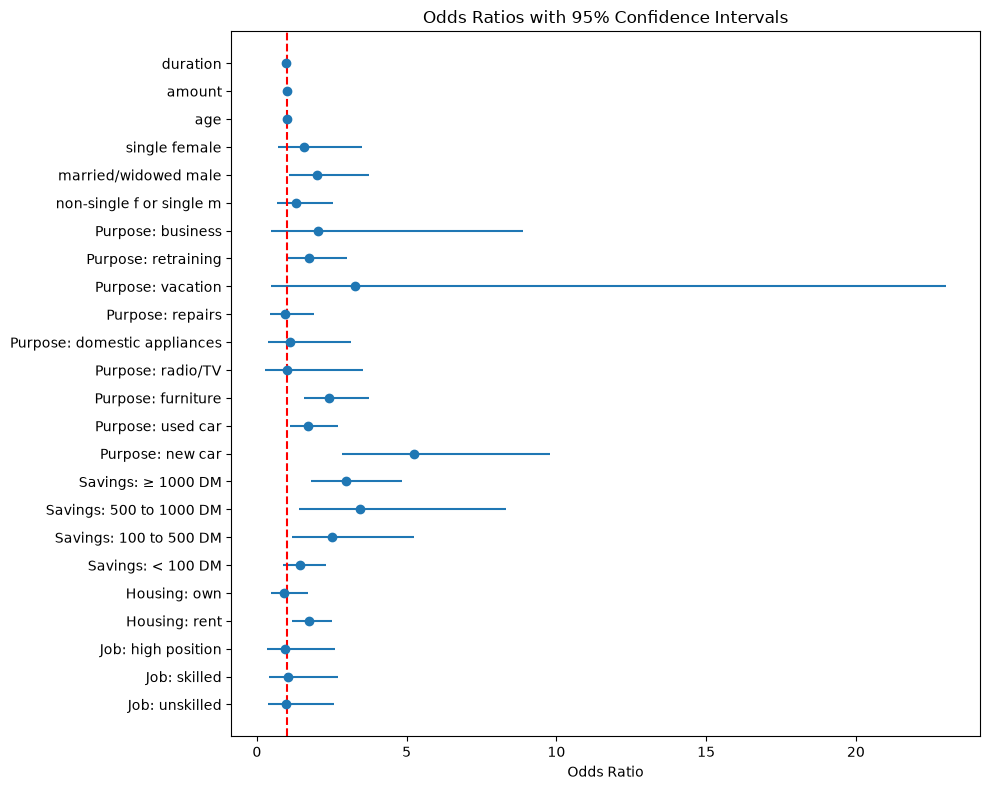

In [13]:
# Let's visualize the odds ratios with 95% confidence intervals [28.10.2026]
conf = results.conf_int()

plot_data = pd.DataFrame({"Odds_Ratio": np.exp(results.params),
                        "Lower": np.exp(conf.iloc[:, 0]),
                        "Upper": np.exp(conf.iloc[:, 1])
})

plot_data = plot_data.drop(index="Intercept", errors="ignore")
labels = [rename_dict.get(str(name), str(name)) for name in plot_data.index]
y = np.arange(len(plot_data))

plt.figure(figsize=(10, 8))
plt.errorbar(
    plot_data["Odds_Ratio"],
    y,
    xerr=[
        plot_data["Odds_Ratio"] - plot_data["Lower"],
        plot_data["Upper"] - plot_data["Odds_Ratio"]
    ],
    fmt="o"
)
plt.axvline(x=1, linestyle="--", color="red")
plt.yticks(y, labels)
plt.xlabel("Odds Ratio")
plt.title("Odds Ratios with 95% Confidence Intervals")
plt.tight_layout()
plt.savefig("odds_ratios_CI.jpg")
plt.show()

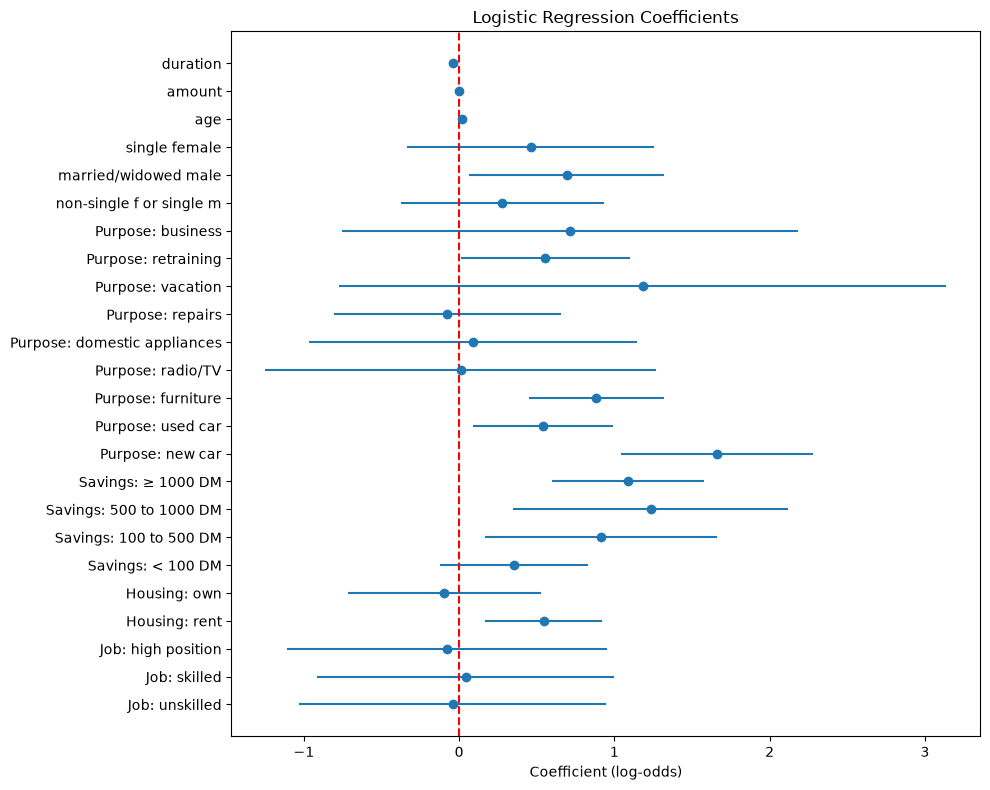

In [14]:
coef = results.params.drop("Intercept", errors="ignore")
conf = results.conf_int().loc[coef.index]
labels = [rename_dict.get(str(name), str(name)) for name in coef.index]
y = range(len(coef))

plt.figure(figsize=(10, 8))
plt.errorbar(
    coef,
    y,
    xerr=[coef - conf.iloc[:, 0], conf.iloc[:, 1] - coef],
    fmt="o"
)
plt.axvline(x=0, linestyle="--", color="red")
plt.yticks(y, labels)
plt.title("Logistic Regression Coefficients")
plt.xlabel("Coefficient (log-odds)")
plt.tight_layout()
plt.savefig("log_regr_coef.jpg")   
plt.show()


In [15]:
# Inspect the exact intervals as numbers for age, amount and duration
pd.DataFrame({
    "coefficient": results.params,
    "ci_lower": results.conf_int()[0],
    "ci_upper": results.conf_int()[1]
}).loc[["age", "amount", "duration"]]

,coefficient,ci_lower,ci_upper
age,0.018395,0.002504,0.034286
amount,-0.000043,-0.000120,0.000035
duration,-0.041070,-0.057605,-0.024534


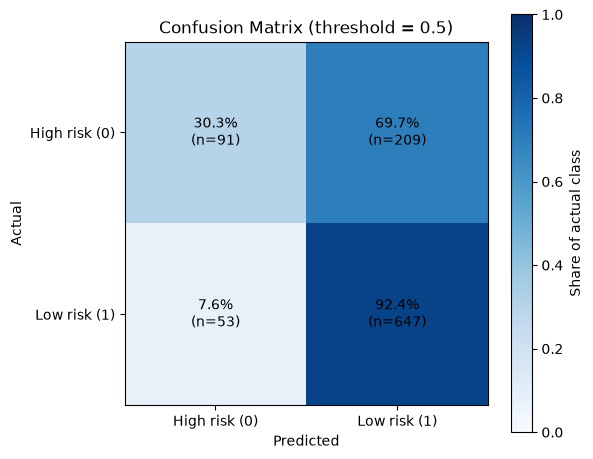

In [18]:
# Let's visualize the confusion matrix [28.10.2026]
threshold = 0.5

pred_prob_dem = results.predict(demographic)
pred_class_dem = (pred_prob_dem >= threshold).astype(int)

# Rows are actual classes; columns are predicted classes.
cm_dem = pd.crosstab(demographic["credit_risk"], pred_class_dem)
cm_dem = cm_dem.reindex(index=[0, 1], columns=[0, 1], fill_value=0)

# Normalize each row to show the share of each actual class.
row_pct_dem = cm_dem.div(cm_dem.sum(axis=1), axis=0).fillna(0)

fig, ax = plt.subplots(figsize=(6, 5))
image_dem = ax.imshow(row_pct_dem.values, cmap="Blues", vmin=0, vmax=1)

for row in range(2):
    for col in range(2):
        ax.text(
            col, row,
            f"{row_pct_dem.iloc[row, col]:.1%}\n(n={cm_dem.iloc[row, col]})",
            ha="center", va="center"
        )

ax.set_xticks([0, 1])
ax.set_xticklabels(["High risk (0)", "Low risk (1)"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["High risk (0)", "Low risk (1)"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Confusion Matrix (threshold = {threshold})")
fig.colorbar(image_dem, ax=ax, label="Share of actual class")
plt.tight_layout()
plt.savefig("CMT_0.5_dem.jpg")
plt.show()

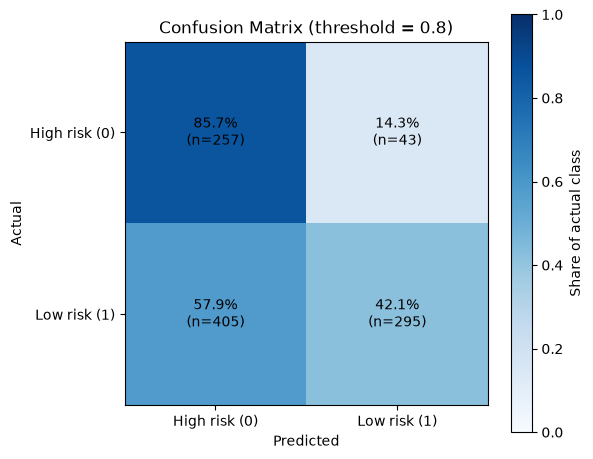

In [19]:
threshold = 0.8

pred_prob_dem = results.predict(demographic)
pred_class_dem = (pred_prob_dem >= threshold).astype(int)

# Rows are actual classes; columns are predicted classes.
cm_dem = pd.crosstab(demographic["credit_risk"], pred_class_dem)
cm_dem = cm_dem.reindex(index=[0, 1], columns=[0, 1], fill_value=0)

# Normalize each row to show the share of each actual class.
row_pct_dem = cm_dem.div(cm_dem.sum(axis=1), axis=0).fillna(0)

fig, ax = plt.subplots(figsize=(6, 5))
image_dem = ax.imshow(row_pct_dem.values, cmap="Blues", vmin=0, vmax=1)

for row in range(2):
    for col in range(2):
        ax.text(
            col, row,
            f"{row_pct_dem.iloc[row, col]:.1%}\n(n={cm_dem.iloc[row, col]})",
            ha="center", va="center"
        )

ax.set_xticks([0, 1])
ax.set_xticklabels(["High risk (0)", "Low risk (1)"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["High risk (0)", "Low risk (1)"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Confusion Matrix (threshold = {threshold})")
fig.colorbar(image_dem, ax=ax, label="Share of actual class")
plt.tight_layout()
plt.savefig("CMT_0.8_dem.jpg")
plt.show()

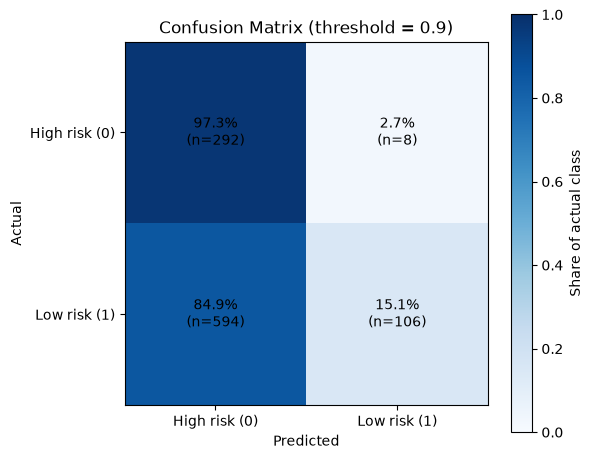

In [20]:
threshold = 0.9

pred_prob_dem = results.predict(demographic)
pred_class_dem = (pred_prob_dem >= threshold).astype(int)

# Rows are actual classes; columns are predicted classes.
cm_dem = pd.crosstab(demographic["credit_risk"], pred_class_dem)
cm_dem = cm_dem.reindex(index=[0, 1], columns=[0, 1], fill_value=0)

# Normalize each row to show the share of each actual class.
row_pct_dem = cm_dem.div(cm_dem.sum(axis=1), axis=0).fillna(0)

fig, ax = plt.subplots(figsize=(6, 5))
image_dem = ax.imshow(row_pct_dem.values, cmap="Blues", vmin=0, vmax=1)

for row in range(2):
    for col in range(2):
        ax.text(
            col, row,
            f"{row_pct_dem.iloc[row, col]:.1%}\n(n={cm_dem.iloc[row, col]})",
            ha="center", va="center"
        )

ax.set_xticks([0, 1])
ax.set_xticklabels(["High risk (0)", "Low risk (1)"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["High risk (0)", "Low risk (1)"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Confusion Matrix (threshold = {threshold})")
fig.colorbar(image_dem, ax=ax, label="Share of actual class")
plt.tight_layout()
plt.savefig("CMT_0.9_dem.jpg")
plt.show()

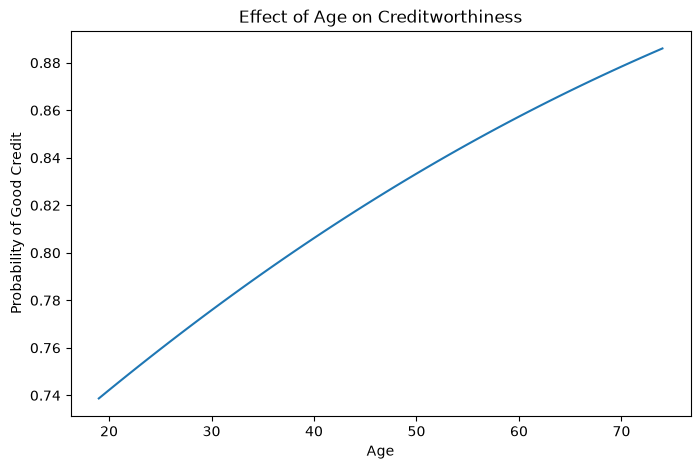

In [21]:
# Effect of Age on Creditworthiness
age_range = np.arange(demographic['age'].min(), demographic['age'].max(), 1)

age_range_df = pd.DataFrame({
    'age': age_range,
    'amount': demographic['amount'].mean(),
    'duration': demographic['duration'].mean(),
    'job': demographic['job'].mode()[0],
    'housing': demographic['housing'].mode()[0],
    'savings': demographic['savings'].mode()[0],
    'purpose': demographic['purpose'].mode()[0],
    'personal_status_sex': demographic['personal_status_sex'].mode()[0]
})

age_range_df['pred_prob'] = results.predict(age_range_df)

plt.figure(figsize=(8,5))
plt.plot(age_range, age_range_df['pred_prob'])
plt.xlabel("Age")
plt.ylabel("Probability of Good Credit")
plt.title("Effect of Age on Creditworthiness")
plt.savefig("age_demogr.jpg")
plt.show()

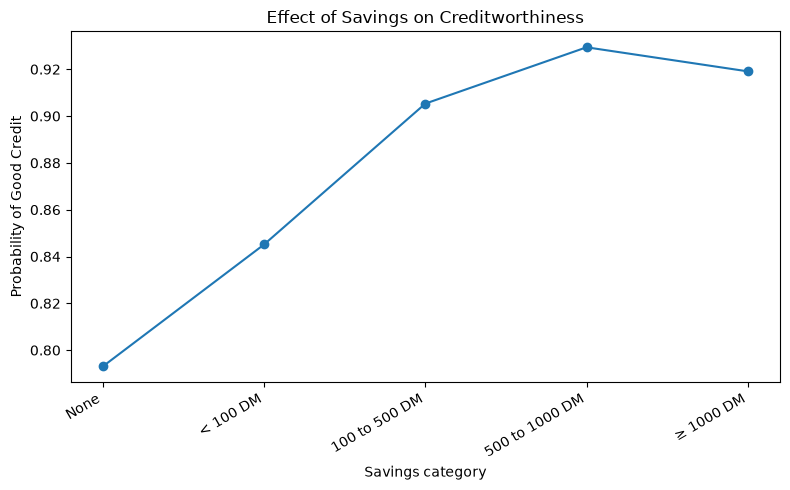

In [22]:
# Effect of Savings on Creditworthiness
savings_labels = {
    1: "None",
    2: "< 100 DM",
    3: "100 to 500 DM",
    4: "500 to 1000 DM",
    5: "≥ 1000 DM"
}

savings_values = sorted(demographic["savings"].dropna().unique())

sav_range = pd.DataFrame({
    "savings": savings_values,
    "amount": demographic["amount"].mean(),
    "duration": demographic["duration"].mean(),
    "age": demographic["age"].mean(),
    "job": demographic["job"].mode()[0],
    "housing": demographic["housing"].mode()[0],
    "purpose": demographic["purpose"].mode()[0],
    'personal_status_sex': demographic['personal_status_sex'].mode()[0]
})

sav_range["pred_prob"] = results.predict(sav_range)

plt.figure(figsize=(8, 5))
plt.plot(sav_range["savings"], sav_range["pred_prob"], marker="o")
plt.xticks(
    savings_values,
    [savings_labels.get(int(code), str(code)) for code in savings_values],
    rotation=30,
    ha="right"
)
plt.xlabel("Savings category")
plt.ylabel("Probability of Good Credit")
plt.title("Effect of Savings on Creditworthiness")
plt.tight_layout()
plt.savefig("savings_on_creditworthiness.jpg")
plt.show()

In [23]:
# RQ 1: Which demographic and financial characteristics influence credit risk? [29.10.26]
    # Dependent variable: credit_risk
    # Independent variables 1.2: age, savings, amount, duration, credit_history, 
                                # status, employment_duration, number_credits, 
                                # present_residence, property

In [24]:
# Define regression function and select variables for smaller data frame
reg_fin = """credit_risk ~ age
            + C(credit_history)
            + C(status)
            + C(savings)
            + amount
            + duration
            + C(employment_duration)
            + C(number_credits)
            + C(present_residence)
            + C(property)"""

financial = df[
    [
        'age',
        'credit_history',
        'status',
        'savings',
        'amount',
        'duration',
        'employment_duration',
        'number_credits',
        'present_residence',
        'property',
        'credit_risk'
    ]
]

In [25]:
# Rename variables
rename_dict_2 = {
    "Intercept": "Intercept",
    "C(credit_history)[T.1]": "Critical Account",
    "C(credit_history)[T.2]": "No Credits",
    "C(credit_history)[T.3]": "Credits Paid Back",
    "C(credit_history)[T.4]": "All Credits at the Bank PB",
    "C(status)[T.2]": "Status: < 0 DM",
    "C(status)[T.3]": "Status: 0 to 200 DM",
    "C(status)[T.4]": "Status: >= 200 DM",
    "C(savings)[T.2]": "Savings: < 100 DM",
    "C(savings)[T.3]": "Savings: 100 to 500 DM",
    "C(savings)[T.4]": "Savings: 500 to 1000 DM",
    "C(savings)[T.5]": "Savings: >= 1000 DM",
    "C(employment_duration)[T.2]": "emp_dur: less than 1 year",
    "C(employment_duration)[T.3]": "emp_dur: 1 to 4 years",
    "C(employment_duration)[T.4]": "emp_dur: 4 to 7 years",
    "C(employment_duration)[T.5]": "emp_dur: 7 or more years",
    "C(number_credits)[T.2]": "Nr.C: 2 to 3",
    "C(number_credits)[T.3]": "Nr.C: 4 to 5",
    "C(number_credits)[T.4]": "Nr.C: 6 or more",
    "C(present_residence)[T.2]": "pres_resid: 1 to 4 yrs",
    "C(present_residence)[T.3]": "pres_resid: 4 to 7 yrs",
    "C(present_residence)[T.4]": "pres_resid: 7 or more yrs",
    "C(property)[T.2]": "Car or Other",
    "C(property)[T.3]": "Building/Life Insurance",
    "C(property)[T.4]": "Real Estate",
    "age": "Age",
    "amount": "Amount",
    "duration": "Duration",
}

# Run the estimation model
logit_model_fin = smf.logit(formula=reg_fin, data=financial)
results_fin = logit_model_fin.fit(cov_type="HC3")
print(results_fin.summary())

Optimization terminated successfully.
         Current function value: 0.485352
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:            credit_risk   No. Observations:                 1000
Model:                          Logit   Df Residuals:                      972
Method:                           MLE   Df Model:                           27
Date:                Tue, 03 Nov 2026   Pseudo R-squ.:                  0.2055
Time:                        09:25:48   Log-Likelihood:                -485.35
converged:                       True   LL-Null:                       -610.86
Covariance Type:                  HC3   LLR p-value:                 3.437e-38
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                       0.2507      0.728      0.344      0.730   

In [26]:
# Obtain Odds Ratios
odds_ratios_fin = pd.DataFrame({
    "Variable": results_fin.params.index,
    "Coefficient": results_fin.params.values,
    "Odds_Ratio": np.exp(results_fin.params.values),
    "p_value": results_fin.pvalues.values
})

# Print table with log-coefficients, odds ratios and p-values
odds_ratios_fin["Variable"] = odds_ratios_fin["Variable"].replace(rename_dict_2)
print(odds_ratios_fin.to_string(formatters={"p_value": "{:.3g}".format}))

                      Variable  Coefficient  Odds_Ratio  p_value
0                    Intercept     0.250736    1.284971     0.73
1             Critical Account    -0.354205    0.701731    0.491
2                   No Credits     0.524061    1.688872    0.188
3            Credits Paid Back     0.829652    2.292521   0.0639
4   All Credits at the Bank PB     1.439788    4.219802 0.000407
5               Status: < 0 DM     0.453337    1.573555   0.0223
6          Status: 0 to 200 DM     1.015577    2.760955  0.00685
7            Status: >= 200 DM     1.769811    5.869741 3.45e-16
8            Savings: < 100 DM     0.210712    1.234557    0.406
9       Savings: 100 to 500 DM     0.494211    1.639204    0.263
10     Savings: 500 to 1000 DM     1.098666    3.000160    0.031
11         Savings: >= 1000 DM     0.841357    2.319512  0.00103
12   emp_dur: less than 1 year    -0.350189    0.704555    0.393
13       emp_dur: 1 to 4 years     0.102934    1.108418     0.79
14       emp_dur: 4 to 7 

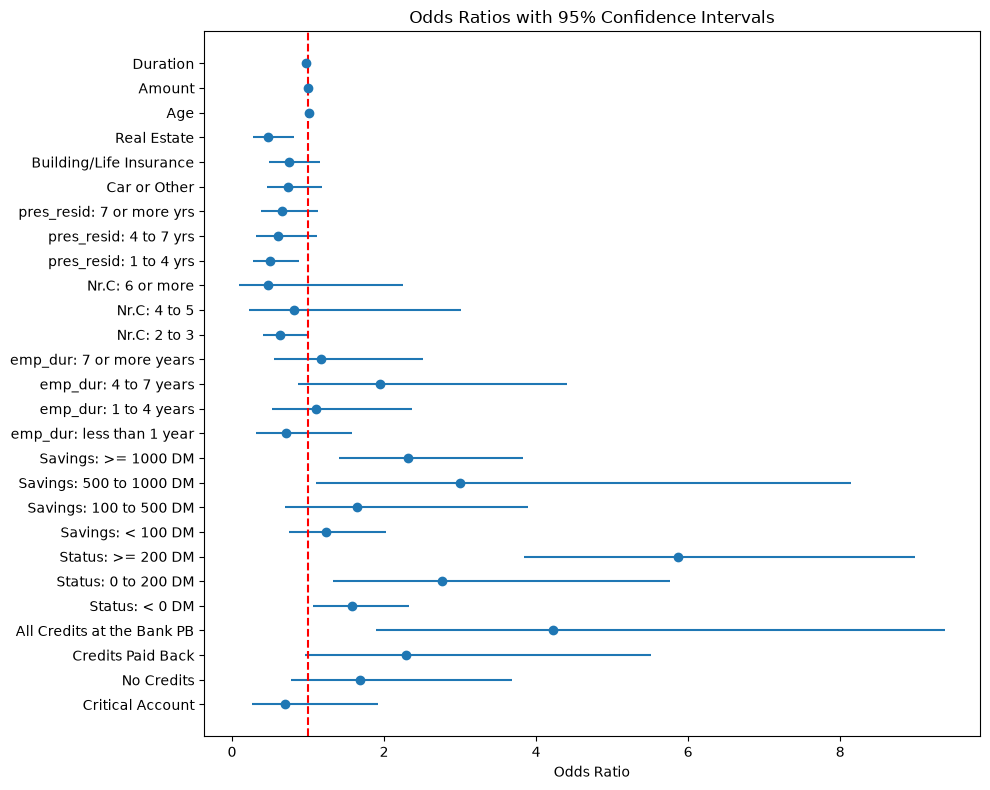

In [27]:
# Let's visualize the odds ratios with 95% confidence intervals
conf_fin = results_fin.conf_int()

plot_data_2 = pd.DataFrame({"Odds_Ratio": np.exp(results_fin.params),
                        "Lower": np.exp(conf_fin.iloc[:, 0]),
                        "Upper": np.exp(conf_fin.iloc[:, 1])
})

plot_data_2 = plot_data_2.drop(index="Intercept", errors="ignore")
labels_fin = [rename_dict_2.get(str(name), str(name)) for name in plot_data_2.index]
y = np.arange(len(plot_data_2))

plt.figure(figsize=(10, 8))
plt.errorbar(
    plot_data_2["Odds_Ratio"],
    y,
    xerr=[
        plot_data_2["Odds_Ratio"] - plot_data_2["Lower"],
        plot_data_2["Upper"] - plot_data_2["Odds_Ratio"]
    ],
    fmt="o"
)
plt.axvline(x=1, linestyle="--", color="red")
plt.yticks(y, labels_fin)
plt.xlabel("Odds Ratio")
plt.title("Odds Ratios with 95% Confidence Intervals")
plt.tight_layout()
plt.savefig("odds_ratios_fin_CI.jpg")
plt.show()

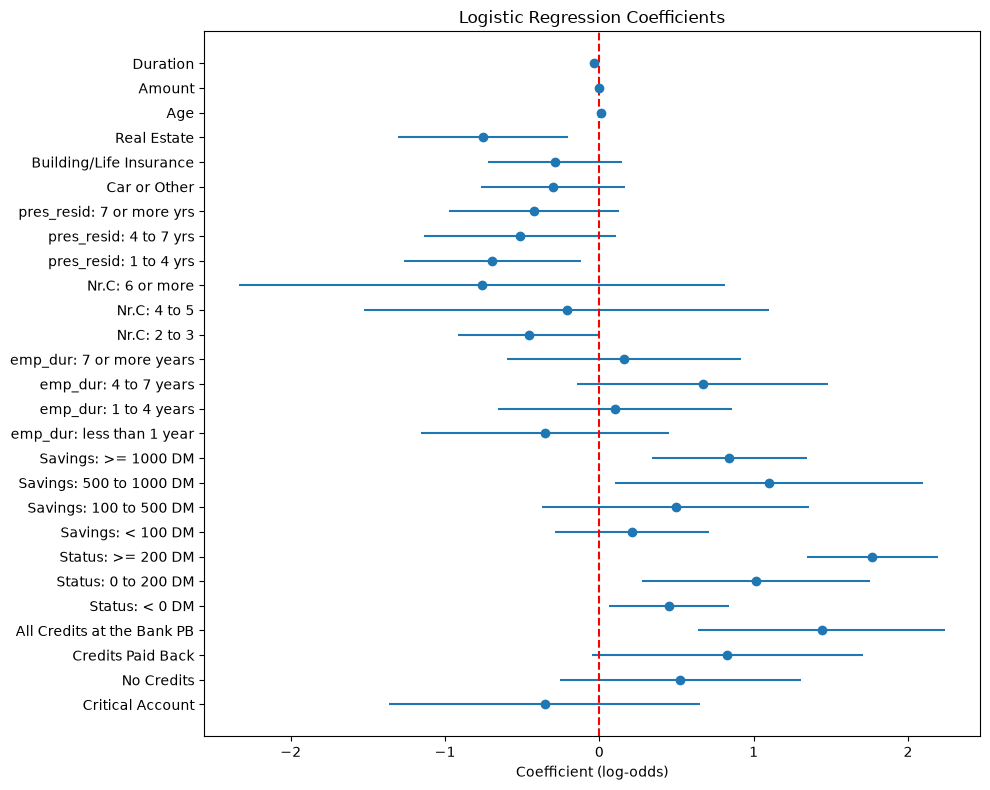

In [28]:
# Plot Log-Regression Coefficients
coef_fin = results_fin.params.drop("Intercept", errors="ignore")
conf_fin = results_fin.conf_int().loc[coef_fin.index]
labels_fin = [rename_dict_2.get(str(name), str(name)) for name in coef_fin.index]
y = range(len(coef_fin))

plt.figure(figsize=(10, 8))
plt.errorbar(coef_fin, y, xerr=[coef_fin - conf_fin.iloc[:, 0], 
                                conf_fin.iloc[:, 1] - coef_fin], fmt="o")
plt.axvline(x=0, linestyle="--", color="red")
plt.yticks(y, labels_fin)
plt.title("Logistic Regression Coefficients")
plt.xlabel("Coefficient (log-odds)")
plt.tight_layout()
plt.savefig("log_regr_fin_coef.jpg")  
plt.show()

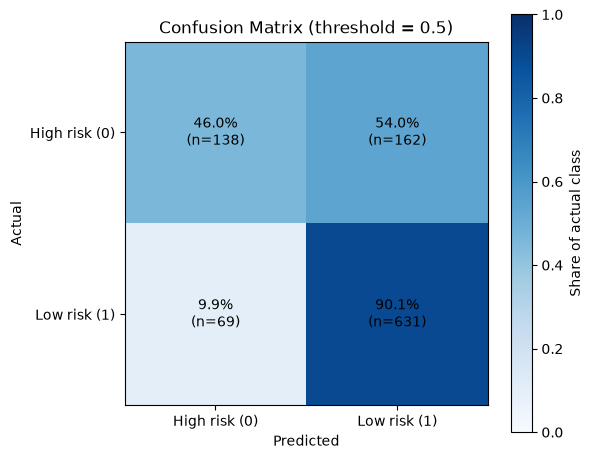

In [30]:
# View the Cofusion Matrix
threshold = 0.5

pred_prob_fin = results_fin.predict(financial)
pred_class_fin = (pred_prob_fin >= threshold).astype(int)

# Rows are actual classes; columns are predicted classes.
cm_fin = pd.crosstab(financial["credit_risk"], pred_class_fin)
cm_fin = cm_fin.reindex(index=[0, 1], columns=[0, 1], fill_value=0)

# Normalize each row to show the share of each actual class.
row_pct_fin = cm_fin.div(cm_fin.sum(axis=1), axis=0).fillna(0)

fig, ax = plt.subplots(figsize=(6, 5))
image_fin = ax.imshow(row_pct_fin.values, cmap="Blues", vmin=0, vmax=1)

for row in range(2):
    for col in range(2):
        ax.text(
            col, row,
            f"{row_pct_fin.iloc[row, col]:.1%}\n(n={cm_fin.iloc[row, col]})",
            ha="center", va="center"
        )

ax.set_xticks([0, 1])
ax.set_xticklabels(["High risk (0)", "Low risk (1)"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["High risk (0)", "Low risk (1)"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Confusion Matrix (threshold = {threshold})")
fig.colorbar(image_fin, ax=ax, label="Share of actual class")
plt.tight_layout()
plt.savefig("CMT_0.5_fin.jpg")
plt.show()

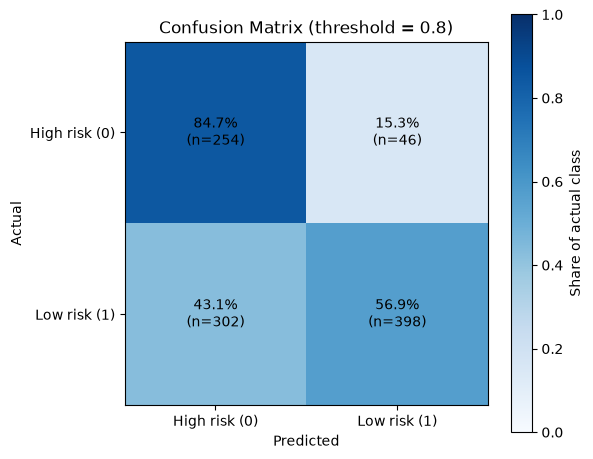

In [31]:
threshold = 0.8

pred_prob_fin = results_fin.predict(financial)
pred_class_fin = (pred_prob_fin >= threshold).astype(int)

# Rows are actual classes; columns are predicted classes.
cm_fin = pd.crosstab(financial["credit_risk"], pred_class_fin)
cm_fin = cm_fin.reindex(index=[0, 1], columns=[0, 1], fill_value=0)

# Normalize each row to show the share of each actual class.
row_pct_fin = cm_fin.div(cm_fin.sum(axis=1), axis=0).fillna(0)

fig, ax = plt.subplots(figsize=(6, 5))
image_fin = ax.imshow(row_pct_fin.values, cmap="Blues", vmin=0, vmax=1)

for row in range(2):
    for col in range(2):
        ax.text(
            col, row,
            f"{row_pct_fin.iloc[row, col]:.1%}\n(n={cm_fin.iloc[row, col]})",
            ha="center", va="center"
        )

ax.set_xticks([0, 1])
ax.set_xticklabels(["High risk (0)", "Low risk (1)"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["High risk (0)", "Low risk (1)"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Confusion Matrix (threshold = {threshold})")
fig.colorbar(image_fin, ax=ax, label="Share of actual class")
plt.tight_layout()
plt.savefig("CMT_0.8_fin.jpg")
plt.show()

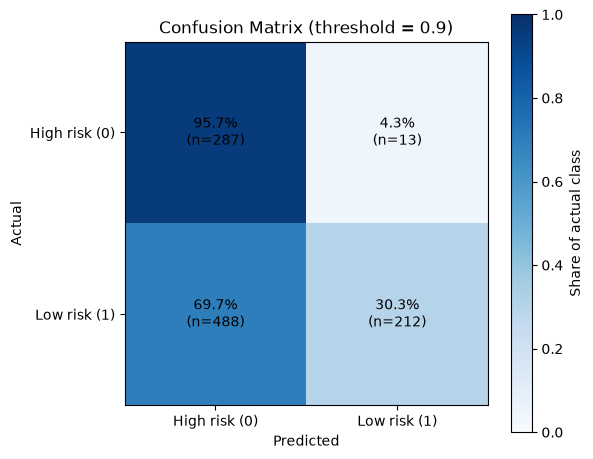

In [32]:
threshold = 0.9

pred_prob_fin = results_fin.predict(financial)
pred_class_fin = (pred_prob_fin >= threshold).astype(int)

# Rows are actual classes; columns are predicted classes.
cm_fin = pd.crosstab(financial["credit_risk"], pred_class_fin)
cm_fin = cm_fin.reindex(index=[0, 1], columns=[0, 1], fill_value=0)

# Normalize each row to show the share of each actual class.
row_pct_fin = cm_fin.div(cm_fin.sum(axis=1), axis=0).fillna(0)

fig, ax = plt.subplots(figsize=(6, 5))
image_fin = ax.imshow(row_pct_fin.values, cmap="Blues", vmin=0, vmax=1)

for row in range(2):
    for col in range(2):
        ax.text(
            col, row,
            f"{row_pct_fin.iloc[row, col]:.1%}\n(n={cm_fin.iloc[row, col]})",
            ha="center", va="center"
        )

ax.set_xticks([0, 1])
ax.set_xticklabels(["High risk (0)", "Low risk (1)"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["High risk (0)", "Low risk (1)"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Confusion Matrix (threshold = {threshold})")
fig.colorbar(image_fin, ax=ax, label="Share of actual class")
plt.tight_layout()
plt.savefig("CMT_0.9_fin.jpg")
plt.show()

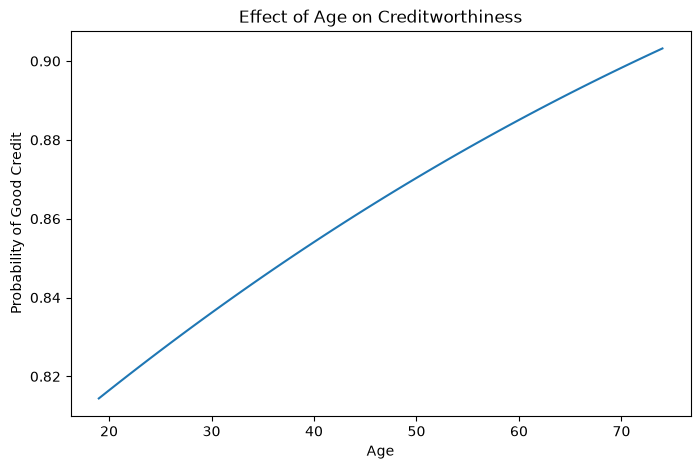

In [33]:
# Effect of Age on Creditworthiness
age_range_fin = np.arange(financial['age'].min(), financial['age'].max(), 1)

age_range_fdf = pd.DataFrame({
    'age': age_range,
    'amount': financial['amount'].mean(),
    'duration': financial['duration'].mean(),
    'credit_history': financial['credit_history'].mode()[0],
    'status': financial['status'].mode()[0],
    'savings': financial['savings'].mode()[0],
    'employment_duration': financial['employment_duration'].mode()[0],
    'number_credits': financial['number_credits'].mode()[0],
    'present_residence': financial['present_residence'].mode()[0],
    'property': financial['property'].mode()[0]
})

age_range_fdf['pred_prob'] = results_fin.predict(age_range_fdf)

plt.figure(figsize=(8,5))
plt.plot(age_range_fin, age_range_fdf['pred_prob'])
plt.xlabel("Age")
plt.ylabel("Probability of Good Credit")
plt.title("Effect of Age on Creditworthiness")
plt.savefig("age_fin.jpg")
plt.show()

# Almost identical with the demographic-set

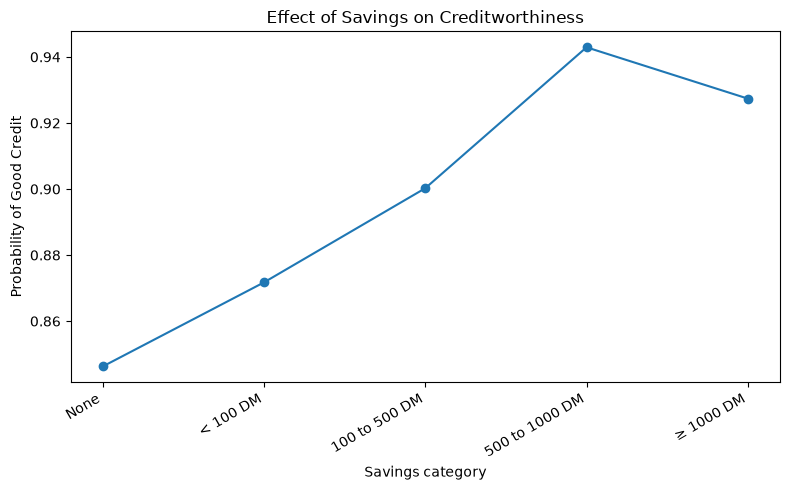

In [34]:
# Effect of Savings on Creditworthiness
savings_labels_fin = {
    1: "None",
    2: "< 100 DM",
    3: "100 to 500 DM",
    4: "500 to 1000 DM",
    5: "≥ 1000 DM"
}

savings_values_fin = sorted(financial["savings"].dropna().unique())

sav_range_fin = pd.DataFrame({
    "savings": savings_values_fin,
    "amount": financial["amount"].mean(),
    "duration": financial["duration"].mean(),
    "age": financial["age"].mean(),
    "credit_history": financial["credit_history"].mode()[0],
    "status": financial["status"].mode()[0],
    "employment_duration": financial["employment_duration"].mode()[0],
    "number_credits": financial["number_credits"].mode()[0],
    "present_residence": financial["present_residence"].mode()[0],
    "property": financial["property"].mode()[0]
})

sav_range_fin["pred_prob"] = results_fin.predict(sav_range_fin)

plt.figure(figsize=(8, 5))
plt.plot(sav_range_fin["savings"], sav_range_fin["pred_prob"], marker="o")
plt.xticks(
    savings_values_fin,
    [savings_labels_fin.get(int(code), str(code)) for code in savings_values_fin],
    rotation=30,
    ha="right"
)
plt.xlabel("Savings category")
plt.ylabel("Probability of Good Credit")
plt.title("Effect of Savings on Creditworthiness")
plt.tight_layout()
plt.savefig("savings_on_creditworthiness_fin.jpg")
plt.show()